# 4A. Keras-only - IMDB Sentiment
Instead of training Word2Vec separately then classifying, Keras trains the embedding **jointly** with the classifier using `TextVectorization` + `Embedding`. Modern + simpler.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

In [2]:
df = pd.read_csv("../../datasets/CBOW/IMDB Dataset.csv")
df = df.sample(10000, random_state=42).reset_index(drop=True)

reviews = df["review"].to_numpy()
y = (df["sentiment"] == "positive").astype(int).to_numpy()

print("samples:", len(reviews))
print("example:", reviews[0][:100], "...")

samples: 10000
example: I really liked this Summerslam due to the look of the arena, the curtains and just the look overall  ...


In [3]:
# tokenize + build vocab from the training text
vectorizer = layers.TextVectorization(max_tokens=10000, output_sequence_length=200)
vectorizer.adapt(reviews)

print("vocab size:", vectorizer.vocabulary_size())

vocab size: 10000


In [4]:
model = keras.Sequential([
    layers.Input(shape=(1,), dtype="string"),
    vectorizer,
    layers.Embedding(10000, 50),
    layers.GlobalAveragePooling1D(),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ (None, 200)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 200, 50)        │       500,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 50)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 501,665 (1.91 MB)

 Trainable params: 501,665 (1.91 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
history = model.fit(reviews, y, validation_split=0.2, epochs=5)

Epoch 1/5
  1/250 ━━━━━━━━━━━━━━━━━━━━ 2:40 645ms/step - accuracy: 0.6562 - loss: 0.6922
 20/250 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4938 - loss: 0.6935
 41/250 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5221 - loss: 0.6929
 62/250 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5580 - loss: 0.6918
 82/250 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5697 - loss: 0.6908
103/250 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5771 - loss: 0.6893
125/250 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5953 - loss: 0.6864
147/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6116 - loss: 0.6813
168/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6179 - loss: 0.6763
189/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6291 - loss: 0.6688
210/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6417 - loss: 0.6592
232/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6536 - loss: 0.6480
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6591 - loss: 0.6403 - val_accur

In [6]:
loss, acc = model.evaluate(reviews, y)
print(f"full-set acc: {acc:.4f}")

  1/313 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 1.0000 - loss: 0.0932

 35/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9723 - loss: 0.1042

 70/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9665 - loss: 0.1123

105/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9690 - loss: 0.1102

140/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9665 - loss: 0.1109

176/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9652 - loss: 0.1130

212/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9674 - loss: 0.1121

248/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9681 - loss: 0.1116

284/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9546 - loss: 0.1395

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9453 - loss: 0.1618


full-set acc: 0.9453


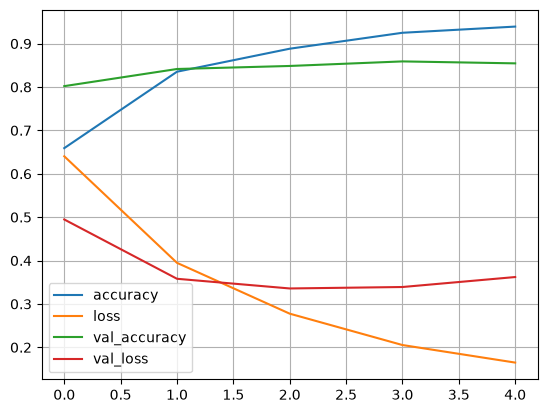

In [7]:
for k, v in history.history.items():
    plt.plot(v, label=k)
plt.legend()
plt.grid()
plt.show()